# Coastal Weather Comparison & Forecasting: Karachi vs. Mumbai

An end-to-end data engineering, exploratory climate analysis, and machine learning project comparing 4 years of hourly coastal weather (`2022-01-01` through `2025-12-31`, `70,128` observations) between **Karachi, Pakistan** and **Mumbai, India** using the **Open-Meteo Historical Weather API (ERA5)**.

### Pipeline Overview
1. **Data Acquisition:** Fetch 4 years of hourly historical observations (`35,064` rows/city) from Open-Meteo ERA5 into `dataset/`.
2. **Data Cleaning & Integration:** Standardize timestamps, coerce numeric metrics safely, deduplicate, and save `dataset/coastal_weather_cleaned.csv` (`70,128` rows).
3. **Exploratory Analysis & Visualizations:** Generate comparative summary statistics and save 6 climate charts to `visualizations/`.
4. **Key Analytical Insights:** Quantify early morning humidity, midday temperature and barometric pressure, and multi-year monsoon rainfall differences.
5. **Predictive Modeling (`model/`):** Engineer causal lag, rolling, and cyclical calendar features, train and benchmark +6-hour temperature forecasting models on a strict chronological split (`2022–2024` train vs. `2025` unseen test), save `model/coastal_weather_temp_forecaster.pkl`, and verify serialized inference.

## 1. Environment Setup

In [1]:
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

os.makedirs('dataset', exist_ok=True)
os.makedirs('model', exist_ok=True)
os.makedirs('visualizations', exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 2. Data Acquisition (Open-Meteo Historical Weather API)

Fetch 4 full years (`2022-01-01` to `2025-12-31`) of hourly ERA5 observations for Karachi (`24.8607°N, 67.0011°E`) and Mumbai (`19.0760°N, 72.8777°E`) in each city's local timezone, saving raw outputs to `dataset/karachi_raw.csv` and `dataset/mumbai_raw.csv`.  
*(Note: Set `RUN_FETCH = True` below to re-fetch live data from Open-Meteo; otherwise, the pipeline uses the cached CSV files in `dataset/`.)*

In [2]:
RUN_FETCH = False
START_DATE = '2022-01-01'
END_DATE = '2025-12-31'
OPEN_METEO_ARCHIVE_URL = 'https://archive-api.open-meteo.com/v1/archive'

WMO_WEATHER_MAP = {
    0: 'Clear sky',
    1: 'Mainly clear',
    2: 'Partly cloudy',
    3: 'Overcast',
    45: 'Fog',
    48: 'Depositing rime fog',
    51: 'Light drizzle',
    53: 'Moderate drizzle',
    55: 'Dense drizzle',
    61: 'Slight rain',
    63: 'Moderate rain',
    65: 'Heavy rain',
    80: 'Slight rain showers',
    81: 'Moderate rain showers',
    82: 'Violent rain showers',
    95: 'Thunderstorm',
    96: 'Thunderstorm with slight hail',
    99: 'Thunderstorm with heavy hail',
}

TARGETS: list[tuple[str, float, float, str, str]] = [
    ('Karachi', 24.8607, 67.0011, 'Asia/Karachi', 'dataset/karachi_raw.csv'),
    ('Mumbai', 19.0760, 72.8777, 'Asia/Kolkata', 'dataset/mumbai_raw.csv'),
]


def fetch_open_meteo_data(
    city: str,
    latitude: float,
    longitude: float,
    timezone: str,
    filename: str,
) -> None:
    print(f"Fetching Open-Meteo hourly archive ({START_DATE} to {END_DATE}) for {city}...")
    params: dict[str, str | float] = {
        'latitude': latitude,
        'longitude': longitude,
        'start_date': START_DATE,
        'end_date': END_DATE,
        'hourly': (
            'temperature_2m,relative_humidity_2m,precipitation,'
            'surface_pressure,wind_speed_10m,wind_direction_10m,weather_code'
        ),
        'timezone': timezone,
    }
    response = requests.get(OPEN_METEO_ARCHIVE_URL, params=params, timeout=60)
    response.raise_for_status()
    hourly = response.json()['hourly']

    df_city = pd.DataFrame({
        'Date & Time': hourly['time'],
        'City': city,
        'Temperature (°C)': hourly['temperature_2m'],
        'Weather Code': hourly['weather_code'],
        'Weather': [WMO_WEATHER_MAP.get(int(code), f'WMO {code}') for code in hourly['weather_code']],
        'Wind Speed (km/h)': hourly['wind_speed_10m'],
        'Wind Direction (°)': hourly['wind_direction_10m'],
        'Humidity (%)': hourly['relative_humidity_2m'],
        'Barometer (mbar)': hourly['surface_pressure'],
        'Precipitation (mm)': hourly['precipitation'],
        'Data Source': 'Open-Meteo ERA5',
    })
    df_city.to_csv(filename, index=False)
    print(f"Saved {len(df_city):,} rows to {filename}")


if RUN_FETCH:
    for city_name, lat, lon, tz, out_path in TARGETS:
        fetch_open_meteo_data(city_name, lat, lon, tz, out_path)
else:
    print("RUN_FETCH is False; using cached Open-Meteo CSV files in dataset/.")

RUN_FETCH is False; using cached Open-Meteo CSV files in dataset/.


## 3. Data Cleaning & Integration

Load the raw Karachi and Mumbai CSV files from `dataset/`, parse ISO-8601 hourly timestamps explicitly, coerce numeric columns safely, remove any duplicates, forward-fill any gaps, and export `dataset/coastal_weather_cleaned.csv`.

In [3]:
def clean_weather_data(city_df: pd.DataFrame, city_name: str) -> pd.DataFrame:
    cleaned = city_df.copy()
    cleaned['Date & Time'] = pd.to_datetime(
        cleaned['Date & Time'],
        format='%Y-%m-%dT%H:%M',
        errors='coerce',
    )
    cleaned = cleaned.sort_values(by='Date & Time')

    numeric_columns = [
        'Temperature (°C)',
        'Weather Code',
        'Wind Speed (km/h)',
        'Wind Direction (°)',
        'Humidity (%)',
        'Barometer (mbar)',
        'Precipitation (mm)',
    ]
    for col in numeric_columns:
        cleaned[col] = pd.to_numeric(cleaned[col], errors='coerce')

    initial_count = len(cleaned)
    cleaned = cleaned.drop_duplicates()
    if len(cleaned) < initial_count:
        print(f"Removed {initial_count - len(cleaned)} duplicate records from {city_name}.")

    return cleaned


df_karachi_raw = pd.read_csv('dataset/karachi_raw.csv')
df_mumbai_raw = pd.read_csv('dataset/mumbai_raw.csv')
print(f"Loaded Karachi: {df_karachi_raw.shape} | Loaded Mumbai: {df_mumbai_raw.shape}")

df_karachi_clean = clean_weather_data(df_karachi_raw, 'Karachi')
df_mumbai_clean = clean_weather_data(df_mumbai_raw, 'Mumbai')

df_combined = pd.concat([df_karachi_clean, df_mumbai_clean], ignore_index=True)

missing_count = int(df_combined.isnull().sum().sum())
if missing_count > 0:
    print(f"Found {missing_count} missing values; applying forward fill...")
    df_combined = df_combined.ffill()

df_combined.to_csv('dataset/coastal_weather_cleaned.csv', index=False)
print(f"Saved cleaned dataset ({len(df_combined):,} rows) to dataset/coastal_weather_cleaned.csv")
display(df_combined.head())

Loaded Karachi: (35064, 11) | Loaded Mumbai: (35064, 11)


Saved cleaned dataset (70,128 rows) to dataset/coastal_weather_cleaned.csv


,Date & Time,City,Temperature (°C),Weather Code,Weather,Wind Speed (km/h),Wind Direction (°),Humidity (%),Barometer (mbar),Precipitation (mm),Data Source
0,2022-01-01 00:00:00,Karachi,15.2,0,Clear sky,21.5,50,62,1021.2,0.0,Open-Meteo ERA5
1,2022-01-01 01:00:00,Karachi,15.0,3,Overcast,21.0,51,64,1020.8,0.0,Open-Meteo ERA5
2,2022-01-01 02:00:00,Karachi,14.8,3,Overcast,20.5,52,64,1020.2,0.0,Open-Meteo ERA5
3,2022-01-01 03:00:00,Karachi,14.7,3,Overcast,20.8,53,65,1019.9,0.0,Open-Meteo ERA5
4,2022-01-01 04:00:00,Karachi,14.6,3,Overcast,19.9,49,66,1019.9,0.0,Open-Meteo ERA5


## 4. Exploratory Data Analysis & Visualizations

### 4.1 Comparative Summary Statistics

In [4]:
def style_summary(frame: pd.DataFrame):
    return (
        frame.style.set_properties(**{'text-align': 'center'})
        .set_table_styles([{'selector': 'th', 'props': [('text-align', 'center'), ('vertical-align', 'middle')]}])
        .format('{:.2f}')
    )


df = pd.read_csv('dataset/coastal_weather_cleaned.csv')
df['Date & Time'] = pd.to_datetime(df['Date & Time'], format='%Y-%m-%d %H:%M:%S')
df['Hour'] = df['Date & Time'].dt.hour
df['DayOfYear'] = df['Date & Time'].dt.day_of_year
df['YearMonth'] = df['Date & Time'].dt.to_period('M').dt.to_timestamp()

summary_stats = df.groupby('City')[
    ['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)', 'Barometer (mbar)', 'Precipitation (mm)']
].agg(['mean', 'median', 'min', 'max', 'std'])
display(style_summary(summary_stats.T))

### 4.2 Multi-Year Monthly Temperature Trend (2022–2025)

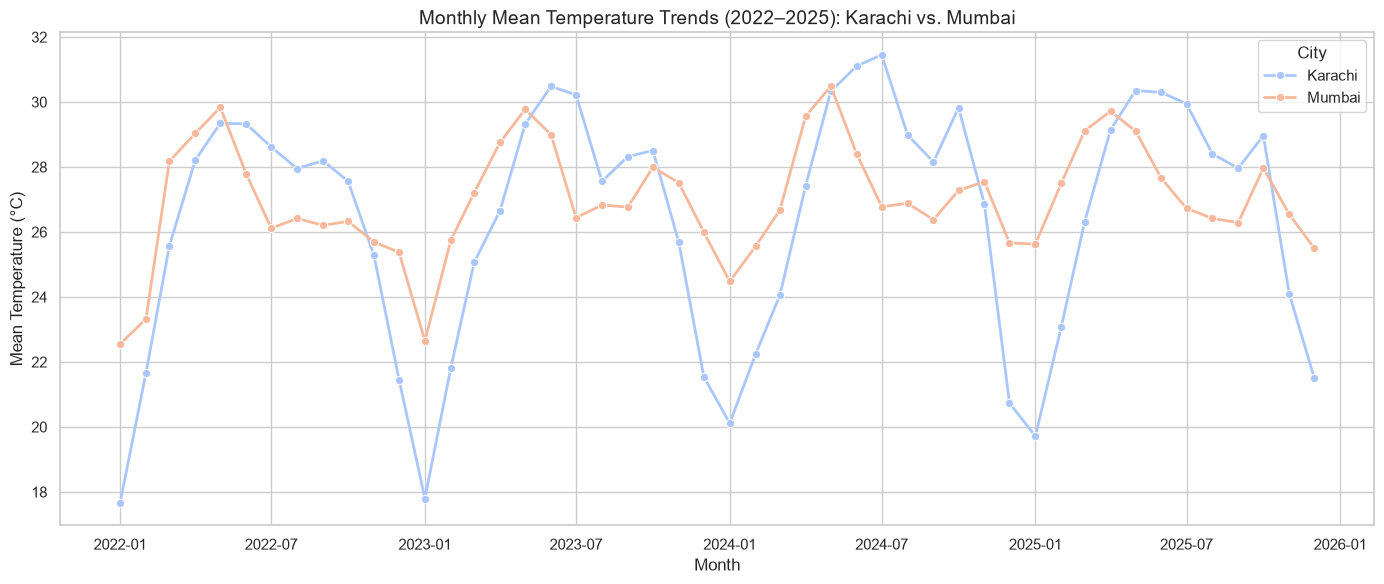

In [5]:
monthly_temp = df.groupby(['YearMonth', 'City'])['Temperature (°C)'].mean().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_temp,
    x='YearMonth',
    y='Temperature (°C)',
    hue='City',
    palette='coolwarm',
    marker='o',
    linewidth=2,
)
plt.title('Monthly Mean Temperature Trends (2022–2025): Karachi vs. Mumbai', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Mean Temperature (°C)')
plt.legend(title='City')
plt.tight_layout()
plt.savefig('visualizations/Temperature_Time_Series_Monthly.png')
plt.show()

**Analysis - Multi-Year Monthly Temperature Trend:**
- **Karachi (Blue):** Exhibits a pronounced continental-coastal seasonal amplitude—monthly averages swing steeply from ~18°C–20°C in January to >31°C in May–June before easing through late summer and autumn.
- **Mumbai (Orange):** Maintains a tighter tropical maritime envelope (~24°C–30°C monthly means), peaking in April–May prior to monsoon onset and cooling noticeably during the June–September southwest monsoon.

### 4.3 Diurnal (Hourly) Temperature Cycle

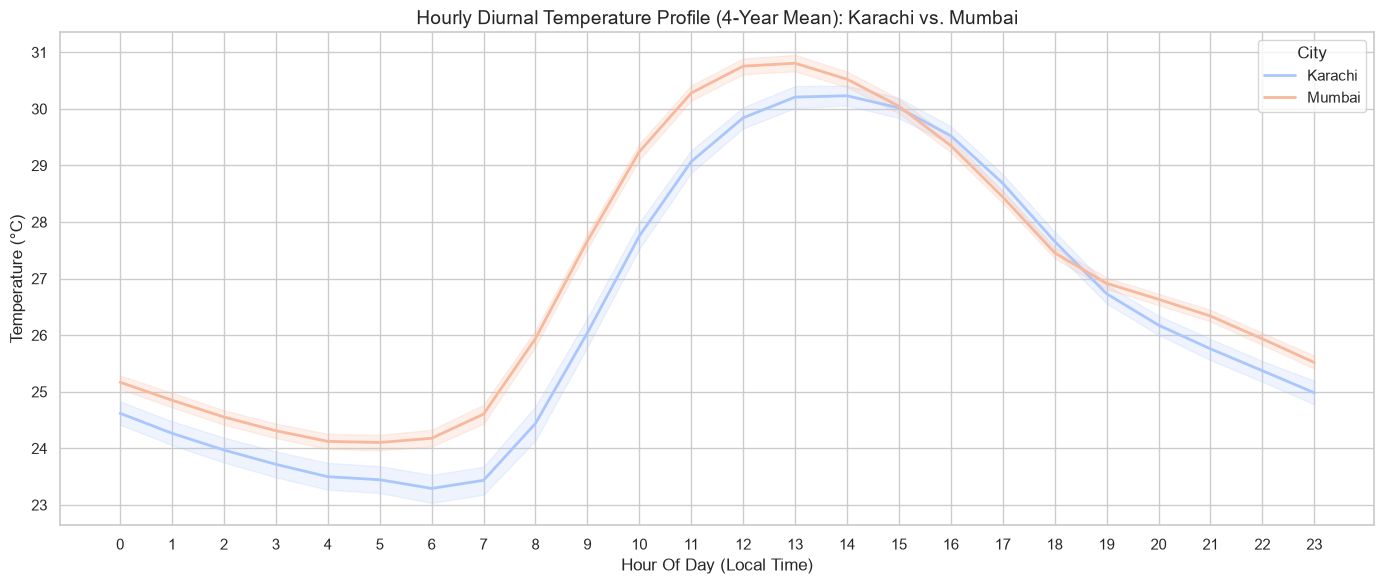

In [6]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=df, x='Hour', y='Temperature (°C)', hue='City', palette='coolwarm', linewidth=2)
plt.title('Hourly Diurnal Temperature Profile (4-Year Mean): Karachi vs. Mumbai', fontsize=14)
plt.xlabel('Hour Of Day (Local Time)')
plt.ylabel('Temperature (°C)')
plt.legend(title='City')
plt.xticks(range(24))
plt.tight_layout()
plt.savefig('visualizations/Temperature_Time_Series_Hourly.png')
plt.show()

**Analysis - Diurnal Temperature Cycle:**
- **Overnight Moderation:** Averaged across all 4 years, Mumbai stays slightly warmer overall (mean 26.99°C vs. Karachi's 26.36°C) and cools more gently overnight.
- **Daytime Heating:** Both cities warm steadily after 06:00 local time and peak around 14:00–15:00, with Karachi showing a slightly wider average diurnal swing due to drier winter/pre-monsoon air masses.

### 4.4 Seasonal Day-of-Year Temperature Climatology

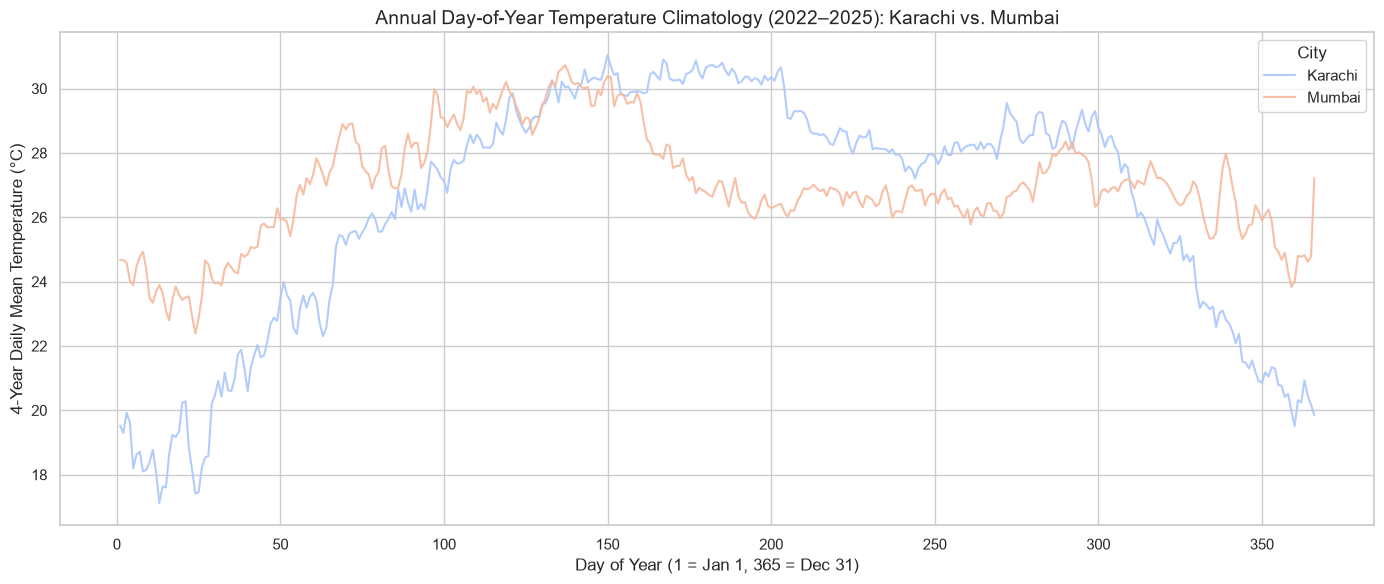

In [7]:
daily_climatology = (
    df.groupby(['DayOfYear', 'City'])['Temperature (°C)']
    .mean()
    .reset_index()
    .sort_values(['City', 'DayOfYear'])
)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=daily_climatology,
    x='DayOfYear',
    y='Temperature (°C)',
    hue='City',
    palette='coolwarm',
    alpha=0.9,
)
plt.title('Annual Day-of-Year Temperature Climatology (2022–2025): Karachi vs. Mumbai', fontsize=14)
plt.xlabel('Day of Year (1 = Jan 1, 365 = Dec 31)')
plt.ylabel('4-Year Daily Mean Temperature (°C)')
plt.legend(title='City')
plt.tight_layout()
plt.savefig('visualizations/Temperature_Time_Series_Daily.png')
plt.show()

**Analysis - Seasonal Day-of-Year Climatology:**
- **Winter Contrast (Days 1–60 & 320–365):** Karachi runs markedly cooler than Mumbai during winter, dropping to an overall hourly minimum of 8.90°C versus Mumbai's 14.30°C.
- **Summer & Monsoon Divergence (Days 140–270):** Karachi sustains hotter mid-summer temperatures through June–August, whereas Mumbai's heavy monsoon cloud cover and rainfall suppress summer highs below Karachi's.

### 4.5 Temperature Distribution

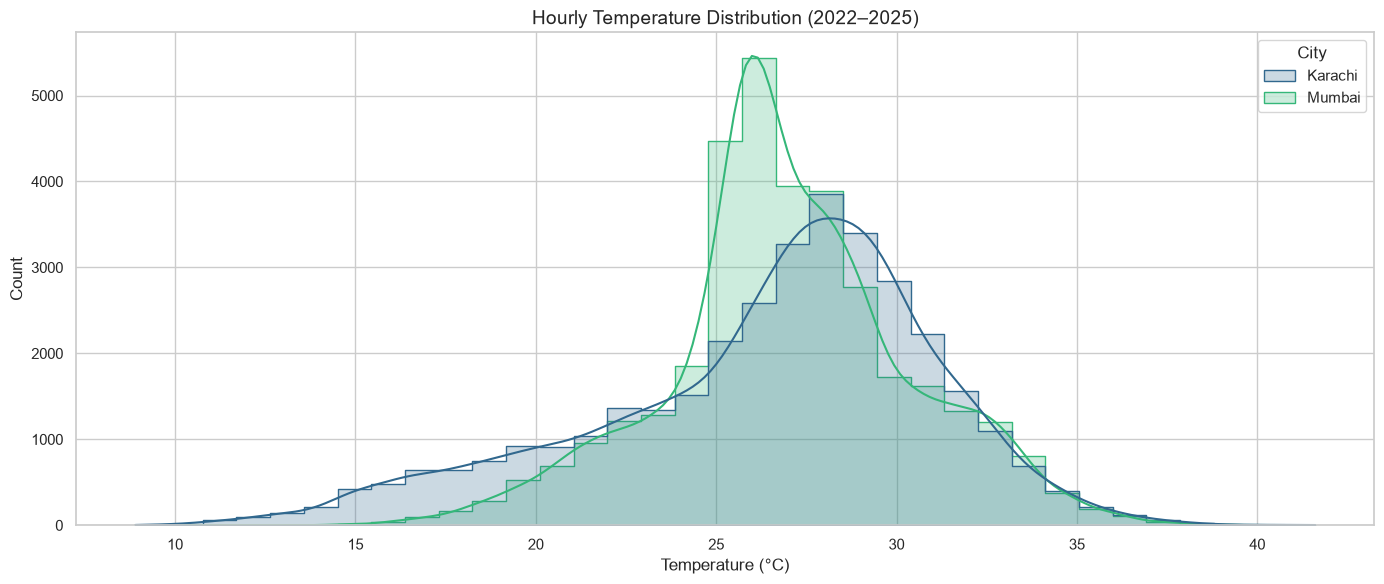

In [8]:
plt.figure(figsize=(14, 6))
sns.histplot(data=df, x='Temperature (°C)', hue='City', bins=35, kde=True, element='step', palette='viridis')
plt.title('Hourly Temperature Distribution (2022–2025)', fontsize=14)
plt.xlabel('Temperature (°C)')
plt.tight_layout()
plt.savefig('visualizations/Temperature_Distribution.png')
plt.show()

**Analysis - Temperature Distribution:**
- **Karachi:** Broad distribution spanning 8.90°C winter lows up to 41.60°C summer peaks (std 4.79°C).
- **Mumbai:** Tighter tropical distribution clustered mostly between 22°C and 32°C (range 14.30°C–41.30°C, std 3.45°C).

### 4.6 Humidity Distribution

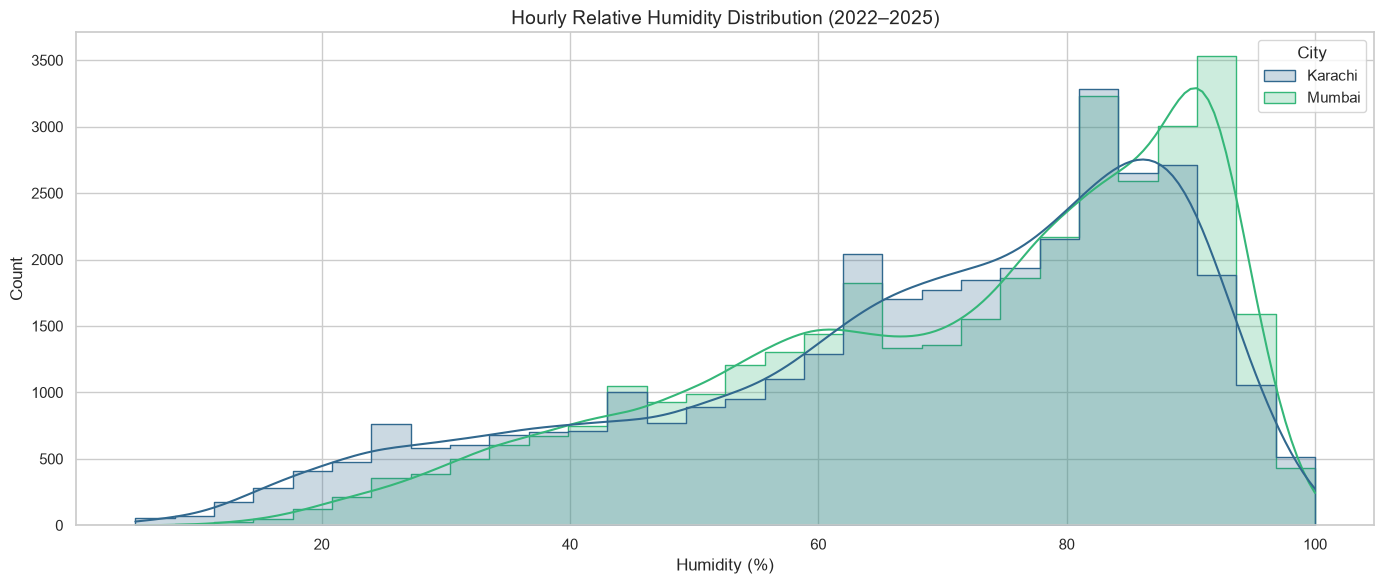

In [9]:
plt.figure(figsize=(14, 6))
sns.histplot(data=df, x='Humidity (%)', hue='City', bins=30, kde=True, element='step', palette='viridis')
plt.title('Hourly Relative Humidity Distribution (2022–2025)', fontsize=14)
plt.xlabel('Humidity (%)')
plt.tight_layout()
plt.savefig('visualizations/Humidity_Distribution.png')
plt.show()

**Analysis - Humidity Distribution:**
- **Mumbai:** More humid overall (mean 71.02%, median 76.00%) with a strong saturation spike above 85%–95% during the monsoon season.
- **Karachi:** Lower average humidity (mean 67.41%, median 72.00%, std 21.18%) with a wider dry tail reaching down to 5% during dry continental winter and pre-monsoon winds.

### 4.7 Wind Speed & Atmospheric Pressure Comparison

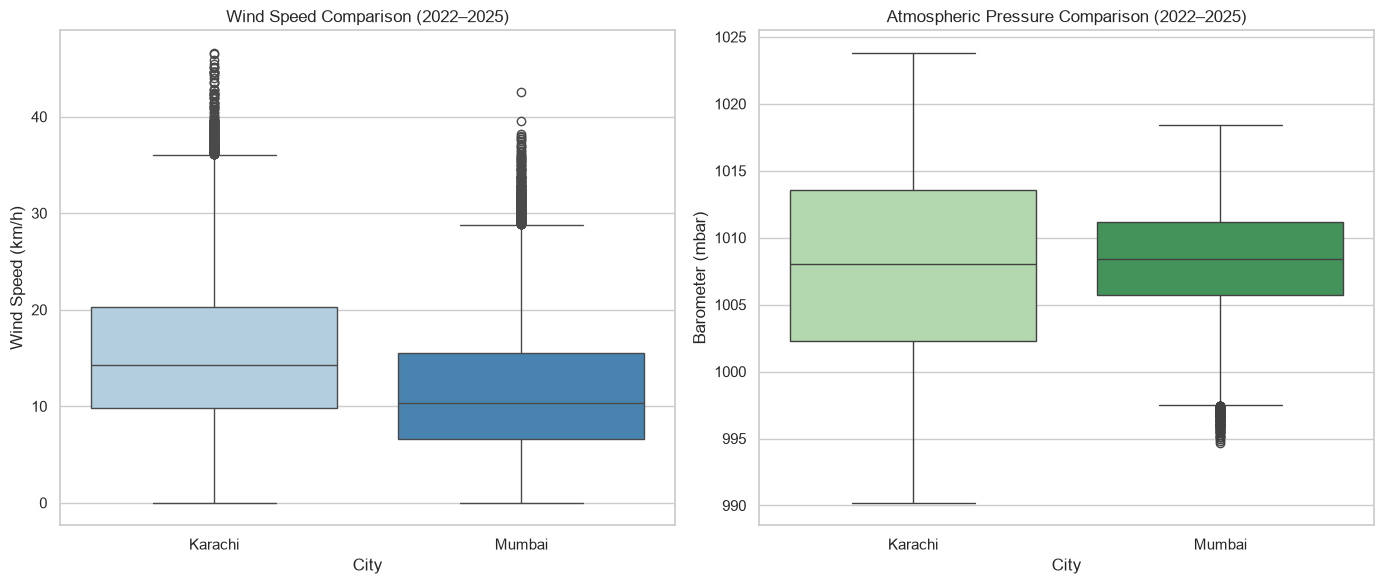

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='vert: bool was deprecated')
    sns.boxplot(data=df, x='City', y='Wind Speed (km/h)', ax=axes[0], hue='City', legend=False, palette='Blues')
    axes[0].set_title('Wind Speed Comparison (2022–2025)')

    sns.boxplot(data=df, x='City', y='Barometer (mbar)', ax=axes[1], hue='City', legend=False, palette='Greens')
    axes[1].set_title('Atmospheric Pressure Comparison (2022–2025)')

plt.tight_layout()
plt.savefig('visualizations/Wind_Pressure_Comparison.png')
plt.show()

**Analysis - Wind & Pressure Dynamics:**
- **Wind Speed:** Across the full 4-year record, Karachi is noticeably windier than Mumbai (mean 15.45 km/h vs. 11.34 km/h; median 14.30 vs. 10.30 km/h), driven by persistent Arabian Sea breezes in summer.
- **Atmospheric Pressure:** Both cities share nearly identical 4-year mean surface pressure (~1007.81 mbar in Karachi vs. 1008.28 mbar in Mumbai), but Karachi exhibits nearly double the seasonal pressure dispersion (std 6.75 vs. 3.79 mbar; range 990.20–1023.80 mbar).

## 5. Key Analytical Insights

In [11]:
def center_align(frame: pd.DataFrame):
    return frame.style.set_properties(**{'text-align': 'center'}).set_table_styles(
        [{'selector': 'th', 'props': [('text-align', 'center')]}]
    )


# 1. Early Morning Humidity (5 AM - 8 AM)
morning_mask = (df['Hour'] >= 5) & (df['Hour'] <= 8)
morning_stats = df.loc[morning_mask].groupby('City')[['Humidity (%)']].mean().round(1)

display(Markdown('### 5.1 Average Early Morning Humidity (5 AM - 8 AM)'))
display(Markdown(
    f"- **Karachi:** {morning_stats.loc['Karachi', 'Humidity (%)']}% mean early-morning relative humidity.\n"
    f"- **Mumbai:** {morning_stats.loc['Mumbai', 'Humidity (%)']}% mean early-morning relative humidity."
))
display(center_align(morning_stats).format('{:.1f}'))

# 2. Midday Temperature & Pressure (12 PM - 2 PM)
noon_mask = (df['Hour'] >= 12) & (df['Hour'] <= 14)
noon_stats = df.loc[noon_mask].groupby('City')[['Temperature (°C)', 'Barometer (mbar)']].mean().round(1)

k_temp = noon_stats.loc['Karachi', 'Temperature (°C)']
k_pres = noon_stats.loc['Karachi', 'Barometer (mbar)']
m_temp = noon_stats.loc['Mumbai', 'Temperature (°C)']
m_pres = noon_stats.loc['Mumbai', 'Barometer (mbar)']

display(Markdown(
    f"### 5.2 Average Midday Temperature & Pressure (12 PM - 2 PM)\n"
    f"- **Temperature:** Karachi ({k_temp}°C) and Mumbai ({m_temp}°C) converge closely at midday across the full year.\n"
    f"- **Pressure:** Mumbai ({m_pres} mbar) averages slightly higher midday pressure than Karachi ({k_pres} mbar)."
))
display(center_align(noon_stats).format('{:.1f}'))

# 3. Rainfall Events & Cumulative Precipitation (2022-2025)
rain_df = df.loc[df['Precipitation (mm)'] > 0]
rain_summary = rain_df.groupby('City').agg(
    Rain_Hours=('Precipitation (mm)', 'count'),
    Total_Rainfall_mm=('Precipitation (mm)', 'sum'),
    Max_Hourly_mm=('Precipitation (mm)', 'max'),
).round(1)

m_rain_hrs = int(float(str(rain_summary.at['Mumbai', 'Rain_Hours'])))
k_rain_hrs = int(float(str(rain_summary.at['Karachi', 'Rain_Hours'])))
m_rain_tot = float(str(rain_summary.at['Mumbai', 'Total_Rainfall_mm']))
k_rain_tot = float(str(rain_summary.at['Karachi', 'Total_Rainfall_mm']))
m_rain_max = float(str(rain_summary.at['Mumbai', 'Max_Hourly_mm']))
k_rain_max = float(str(rain_summary.at['Karachi', 'Max_Hourly_mm']))

display(Markdown('### 5.3 Multi-Year Rainfall Summary (2022–2025)'))
display(Markdown(
    f"- **Mumbai:** {m_rain_hrs:,} rain hours totaling **{m_rain_tot:,.1f} mm** (max {m_rain_max:.1f} mm/h).\n"
    f"- **Karachi:** {k_rain_hrs:,} rain hours totaling **{k_rain_tot:,.1f} mm** (max {k_rain_max:.1f} mm/h)."
))
display(center_align(rain_summary).format({'Rain_Hours': '{:,}', 'Total_Rainfall_mm': '{:,.1f}', 'Max_Hourly_mm': '{:.1f}'}))

### 5.1 Average Early Morning Humidity (5 AM - 8 AM)

- **Karachi:** 78.1% mean early-morning relative humidity.
- **Mumbai:** 78.4% mean early-morning relative humidity.

,Humidity (%)
City,
Karachi,78.1
Mumbai,78.4


### 5.2 Average Midday Temperature & Pressure (12 PM - 2 PM)
- **Temperature:** Karachi (30.1°C) and Mumbai (30.7°C) converge closely at midday across the full year.
- **Pressure:** Mumbai (1007.9 mbar) averages slightly higher midday pressure than Karachi (1007.8 mbar).

,Temperature (°C),Barometer (mbar)
City,,
Karachi,30.1,1007.8
Mumbai,30.7,1007.9


### 5.3 Multi-Year Rainfall Summary (2022–2025)

- **Mumbai:** 9,892 rain hours totaling **9,891.2 mm** (max 25.3 mm/h).
- **Karachi:** 2,473 rain hours totaling **1,555.3 mm** (max 43.2 mm/h).

,Rain_Hours,Total_Rainfall_mm,Max_Hourly_mm
City,,,
Karachi,"2,473","1,555.3",43.2
Mumbai,"9,892","9,891.2",25.3


## 6. Predictive Modeling: +6-Hour Temperature Forecasting

Using the multi-year hourly archive (`70,128` rows), we build a strictly causal forecasting pipeline to predict **temperature 6 hours ahead (`Target_Temp_6h`)** for both Karachi and Mumbai:
- **Causal Features (`21` predictors):** City indicator (`City_Is_Mumbai`), current meteorological readings (`Temperature`, `Humidity`, `Barometer`, `Wind Speed`, `Wind Direction`, `Precipitation`), lag/difference features (`1h`, `3h`, `6h`, `24h`), 24-hour rolling temperature mean & standard deviation, and cyclical time encodings (`Hour_Sin/Cos`, `DayOfYear_Sin/Cos`).
- **Strict Chronological Split:** Train on `2022-01-01` through `2024-12-31` (`52,560` rows) and evaluate on the completely unseen `2025` calendar year (`17,508` rows).
- **Artifact Export:** Persist the winning estimator and feature contract to `model/coastal_weather_temp_forecaster.pkl` and verify exact prediction parity after reloading from disk.

Modeling rows: 70,068 | Train (2022–2024): 52,560 | Test (2025): 17,508


,MAE (°C),RMSE (°C),R²
Model,,,
Persistence Baseline,3.1892,4.1348,-0.0657
Ridge Regression,1.1558,1.5073,0.8584
Random Forest (depth=14),0.6877,0.9632,0.9422
HistGradientBoosting,0.6516,0.9064,0.9488


Saved HistGradientBoosting to model/coastal_weather_temp_forecaster.pkl (0.44 MB) | Reload max_diff = 0.000000


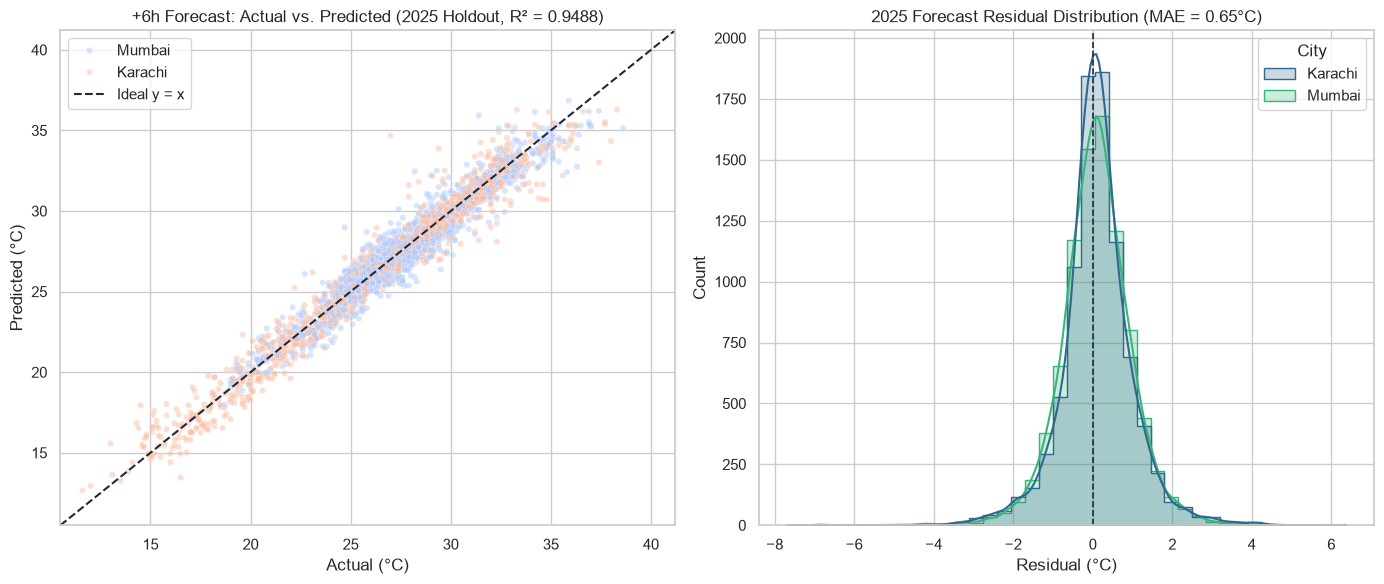

In [12]:
HORIZON_HOURS = 6

feature_frames = []
for _city, city_group in df.groupby('City', sort=False):
    g = city_group.sort_values('Date & Time').copy()
    g['Temp_Lag_1h'] = g['Temperature (°C)'].shift(1)
    g['Temp_Lag_3h'] = g['Temperature (°C)'].shift(3)
    g['Temp_Lag_6h'] = g['Temperature (°C)'].shift(6)
    g['Temp_Lag_24h'] = g['Temperature (°C)'].shift(24)
    g['Temp_Diff_1h'] = g['Temperature (°C)'] - g['Temp_Lag_1h']
    g['Temp_Diff_3h'] = g['Temperature (°C)'] - g['Temp_Lag_3h']
    g['Pressure_Diff_3h'] = g['Barometer (mbar)'] - g['Barometer (mbar)'].shift(3)
    g['Humidity_Diff_3h'] = g['Humidity (%)'] - g['Humidity (%)'].shift(3)
    g['Temp_RollMean_24h'] = g['Temperature (°C)'].rolling(24).mean()
    g['Temp_RollStd_24h'] = g['Temperature (°C)'].rolling(24).std()
    g['Target_Temp_6h'] = g['Temperature (°C)'].shift(-HORIZON_HOURS)
    feature_frames.append(g)

ml_df = pd.concat(feature_frames, ignore_index=True).dropna().reset_index(drop=True)
ml_df['City_Is_Mumbai'] = (ml_df['City'] == 'Mumbai').astype(int)
ml_df['Hour_Sin'] = np.sin(2 * np.pi * ml_df['Hour'] / 24.0)
ml_df['Hour_Cos'] = np.cos(2 * np.pi * ml_df['Hour'] / 24.0)
ml_df['DayOfYear_Sin'] = np.sin(2 * np.pi * ml_df['DayOfYear'] / 365.25)
ml_df['DayOfYear_Cos'] = np.cos(2 * np.pi * ml_df['DayOfYear'] / 365.25)

FEATURE_COLUMNS = [
    'City_Is_Mumbai',
    'Temperature (°C)',
    'Humidity (%)',
    'Barometer (mbar)',
    'Wind Speed (km/h)',
    'Wind Direction (°)',
    'Precipitation (mm)',
    'Temp_Lag_1h',
    'Temp_Lag_3h',
    'Temp_Lag_6h',
    'Temp_Lag_24h',
    'Temp_Diff_1h',
    'Temp_Diff_3h',
    'Pressure_Diff_3h',
    'Humidity_Diff_3h',
    'Temp_RollMean_24h',
    'Temp_RollStd_24h',
    'Hour_Sin',
    'Hour_Cos',
    'DayOfYear_Sin',
    'DayOfYear_Cos',
]

split_cutoff = pd.Timestamp('2025-01-01 00:00:00')
train_df = ml_df.loc[ml_df['Date & Time'] < split_cutoff].copy()
test_df = ml_df.loc[ml_df['Date & Time'] >= split_cutoff].copy()

X_train, y_train = train_df[FEATURE_COLUMNS], train_df['Target_Temp_6h']
X_test, y_test = test_df[FEATURE_COLUMNS], test_df['Target_Temp_6h']
print(f"Modeling rows: {len(ml_df):,} | Train (2022–2024): {len(train_df):,} | Test (2025): {len(test_df):,}")

candidates = {
    'Persistence Baseline': None,
    'Ridge Regression': Pipeline([('scaler', StandardScaler()), ('regressor', Ridge(alpha=1.0))]),
    'Random Forest (depth=14)': RandomForestRegressor(n_estimators=100, max_depth=14, n_jobs=-1, random_state=42),
    'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=8, random_state=42),
}

results = []
predictions = {}
for name, estimator in candidates.items():
    if estimator is None:
        preds = test_df['Temperature (°C)'].to_numpy()
    else:
        estimator.fit(X_train, y_train)
        preds = np.asarray(estimator.predict(X_test), dtype=float)
    predictions[name] = preds
    results.append({
        'Model': name,
        'MAE (°C)': round(float(mean_absolute_error(y_test, preds)), 4),
        'RMSE (°C)': round(float(root_mean_squared_error(y_test, preds)), 4),
        'R²': round(float(r2_score(y_test, preds)), 4),
    })

benchmark_df = pd.DataFrame(results).set_index('Model')
display(center_align(benchmark_df).format('{:.4f}'))

best_model_name = 'HistGradientBoosting'
best_model = candidates[best_model_name]
assert best_model is not None
best_preds = np.asarray(predictions[best_model_name], dtype=float)

test_eval = test_df[['Date & Time', 'City']].copy()
test_eval['Actual (°C)'] = y_test.to_numpy()
test_eval['Predicted (°C)'] = best_preds
test_eval['Residual (°C)'] = test_eval['Actual (°C)'] - test_eval['Predicted (°C)']

per_city_metrics = {}
for city_name, grp in test_eval.groupby('City'):
    per_city_metrics[str(city_name)] = {
        'mae': round(float(mean_absolute_error(grp['Actual (°C)'], grp['Predicted (°C)'])), 4),
        'rmse': round(float(root_mean_squared_error(grp['Actual (°C)'], grp['Predicted (°C)'])), 4),
        'r2': round(float(r2_score(grp['Actual (°C)'], grp['Predicted (°C)'])), 4),
    }

best_mae = float(str(benchmark_df.at[best_model_name, 'MAE (°C)']))
best_rmse = float(str(benchmark_df.at[best_model_name, 'RMSE (°C)']))
best_r2 = float(str(benchmark_df.at[best_model_name, 'R²']))

model_path = 'model/coastal_weather_temp_forecaster.pkl'
model_artifact = {
    'model_name': best_model_name,
    'estimator': best_model,
    'feature_columns': FEATURE_COLUMNS,
    'target_column': 'Target_Temp_6h',
    'horizon_hours': HORIZON_HOURS,
    'train_rows': len(train_df),
    'test_rows': len(test_df),
    'test_metrics': {
        'mae': best_mae,
        'rmse': best_rmse,
        'r2': best_r2,
        'per_city': per_city_metrics,
    },
}
joblib.dump(model_artifact, model_path, compress=3)

loaded_artifact = joblib.load(model_path)
reloaded_preds = loaded_artifact['estimator'].predict(X_test)
max_diff = float(np.max(np.abs(reloaded_preds - best_preds)))
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"Saved {best_model_name} to {model_path} ({model_size_mb:.2f} MB) | Reload max_diff = {max_diff:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(
    data=test_eval.sample(n=3000, random_state=42),
    x='Actual (°C)',
    y='Predicted (°C)',
    hue='City',
    alpha=0.45,
    s=20,
    palette='coolwarm',
    ax=axes[0],
)
lims = [float(test_eval['Actual (°C)'].min()) - 1, float(test_eval['Actual (°C)'].max()) + 1]
axes[0].plot(lims, lims, '--', color='#1f2937', linewidth=1.5, label='Ideal y = x')
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_title(f"+6h Forecast: Actual vs. Predicted (2025 Holdout, R² = {best_r2:.4f})")
axes[0].legend()

sns.histplot(data=test_eval, x='Residual (°C)', hue='City', bins=40, kde=True, element='step', palette='viridis', ax=axes[1])
axes[1].axvline(0.0, color='#1f2937', linestyle='--', linewidth=1.2)
axes[1].set_title(f"2025 Forecast Residual Distribution (MAE = {best_mae:.2f}°C)")

plt.tight_layout()
plt.savefig('visualizations/Model_Evaluation.png')
plt.show()

## 7. Trained Model Inference Demonstration

To demonstrate that `model/coastal_weather_temp_forecaster.pkl` works end-to-end as a standalone predictor:
1. **Disk Reload & Metadata Inspection:** Load the serialized model artifact independently via `joblib.load`.
2. **Unseen 2025 Seasonal Spot-Checks:** Predict +6-hour temperatures across Winter, Summer, Monsoon, and Autumn timestamps for both Karachi and Mumbai and compare directly against ground-truth observations.
3. **Custom Standalone Observation Inference:** Construct single observation payloads matching `feature_columns` to verify real-time inference without the training table.
4. **7-Day Chronological Forecast Overlay:** Plot actual vs. predicted +6-hour temperatures across a continuous week in June 2025 (`visualizations/Forecast_Demonstration.png`).

Loaded model: HistGradientBoosting | Horizon: +6h | Features: 21 | 2025 Test R²: 0.9488


### 7.1 Unseen 2025 Seasonal Forecast Spot-Checks

,City,Observation (t),Current Temp (°C),Target Time (t+6h),Actual +6h (°C),Predicted +6h (°C),Error (°C)
0,Karachi,2025-01-15 08:00,15.0,2025-01-15 14:00,24.8,23.90,-0.90
1,Mumbai,2025-01-15 08:00,23.4,2025-01-15 14:00,28.6,31.23,2.63
2,Karachi,2025-05-20 08:00,30.2,2025-05-20 14:00,33.2,32.57,-0.63
3,Mumbai,2025-05-20 08:00,30.0,2025-05-20 14:00,30.9,33.32,2.42
4,Karachi,2025-07-15 08:00,29.8,2025-07-15 14:00,31.9,32.01,0.11
5,Mumbai,2025-07-15 08:00,27.4,2025-07-15 14:00,27.6,27.08,-0.52
6,Karachi,2025-11-10 18:00,25.4,2025-11-11 00:00,22.5,21.67,-0.83
7,Mumbai,2025-11-10 18:00,27.5,2025-11-11 00:00,24.2,23.43,-0.77


### 7.2 Custom Single-Observation Inference
- **Karachi Summer Morning (29.5°C at 08:00):** Predicted temperature at 14:00 (+6h) = **32.86°C**
- **Mumbai Monsoon Afternoon (27.8°C at 14:00, 2.4 mm rain):** Predicted temperature at 20:00 (+6h) = **26.47°C**

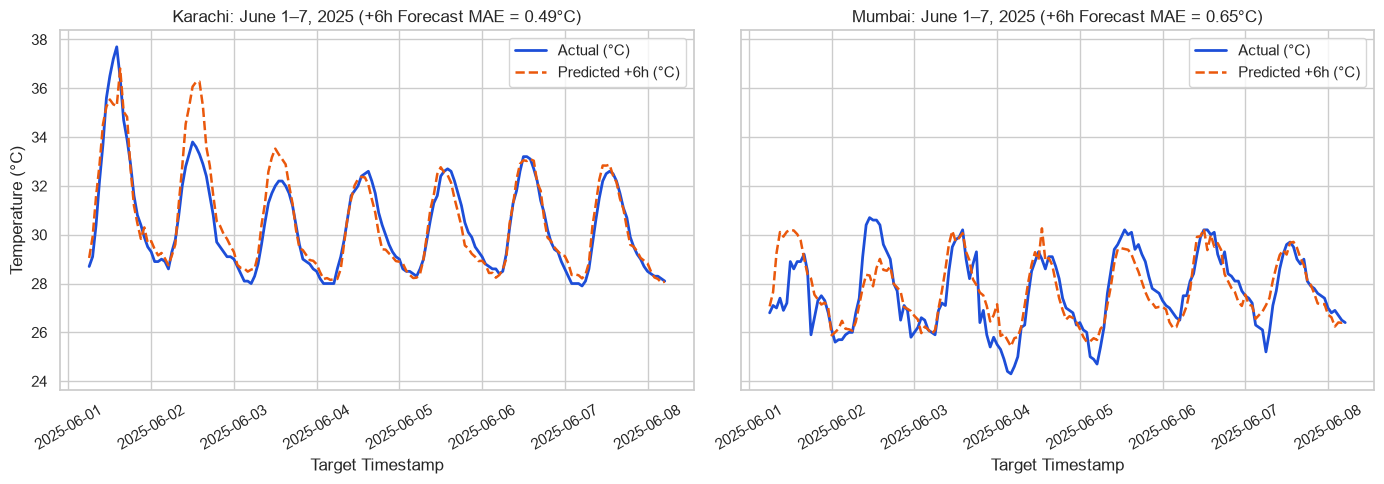

In [13]:
# 1. Load persisted model bundle independently from disk
bundle = joblib.load('model/coastal_weather_temp_forecaster.pkl')
loaded_estimator = bundle['estimator']
model_features: list[str] = bundle['feature_columns']
horizon: int = bundle['horizon_hours']

print(
    f"Loaded model: {bundle['model_name']} | Horizon: +{horizon}h | "
    f"Features: {len(model_features)} | 2025 Test R²: {bundle['test_metrics']['r2']:.4f}"
)

# 2. Seasonal spot-checks on unseen 2025 observations
demo_timestamps = pd.to_datetime([
    '2025-01-15 08:00:00',
    '2025-05-20 08:00:00',
    '2025-07-15 08:00:00',
    '2025-11-10 18:00:00',
])
spot_df = test_df.loc[test_df['Date & Time'].isin(demo_timestamps)].copy()
spot_preds = np.asarray(loaded_estimator.predict(spot_df[model_features]), dtype=float)

demo_table = pd.DataFrame({
    'City': spot_df['City'].to_numpy(),
    'Observation (t)': spot_df['Date & Time'].dt.strftime('%Y-%m-%d %H:%M').to_numpy(),
    'Current Temp (°C)': spot_df['Temperature (°C)'].to_numpy(),
    'Target Time (t+6h)': (spot_df['Date & Time'] + pd.Timedelta(hours=horizon)).dt.strftime('%Y-%m-%d %H:%M').to_numpy(),
    'Actual +6h (°C)': spot_df['Target_Temp_6h'].to_numpy(),
    'Predicted +6h (°C)': np.round(spot_preds, 2),
    'Error (°C)': np.round(spot_preds - spot_df['Target_Temp_6h'].to_numpy(), 2),
}).sort_values(['Observation (t)', 'City']).reset_index(drop=True)

display(Markdown('### 7.1 Unseen 2025 Seasonal Forecast Spot-Checks'))
display(demo_table)

# 3. Standalone single-row inference from custom weather payloads
custom_observations = pd.DataFrame([
    {
        'City_Is_Mumbai': 0,  # Karachi summer morning (08:00, Day 150)
        'Temperature (°C)': 29.5,
        'Humidity (%)': 70.0,
        'Barometer (mbar)': 1003.0,
        'Wind Speed (km/h)': 18.0,
        'Wind Direction (°)': 245.0,
        'Precipitation (mm)': 0.0,
        'Temp_Lag_1h': 28.4,
        'Temp_Lag_3h': 27.1,
        'Temp_Lag_6h': 26.8,
        'Temp_Lag_24h': 29.1,
        'Temp_Diff_1h': 1.1,
        'Temp_Diff_3h': 2.4,
        'Pressure_Diff_3h': 0.8,
        'Humidity_Diff_3h': -6.0,
        'Temp_RollMean_24h': 30.2,
        'Temp_RollStd_24h': 2.1,
        'Hour_Sin': float(np.sin(2 * np.pi * 8 / 24.0)),
        'Hour_Cos': float(np.cos(2 * np.pi * 8 / 24.0)),
        'DayOfYear_Sin': float(np.sin(2 * np.pi * 150 / 365.25)),
        'DayOfYear_Cos': float(np.cos(2 * np.pi * 150 / 365.25)),
    },
    {
        'City_Is_Mumbai': 1,  # Mumbai monsoon afternoon (14:00, Day 200)
        'Temperature (°C)': 27.8,
        'Humidity (%)': 88.0,
        'Barometer (mbar)': 1005.5,
        'Wind Speed (km/h)': 16.0,
        'Wind Direction (°)': 230.0,
        'Precipitation (mm)': 2.4,
        'Temp_Lag_1h': 27.9,
        'Temp_Lag_3h': 27.5,
        'Temp_Lag_6h': 26.4,
        'Temp_Lag_24h': 27.6,
        'Temp_Diff_1h': -0.1,
        'Temp_Diff_3h': 0.3,
        'Pressure_Diff_3h': -0.5,
        'Humidity_Diff_3h': 2.0,
        'Temp_RollMean_24h': 27.1,
        'Temp_RollStd_24h': 0.9,
        'Hour_Sin': float(np.sin(2 * np.pi * 14 / 24.0)),
        'Hour_Cos': float(np.cos(2 * np.pi * 14 / 24.0)),
        'DayOfYear_Sin': float(np.sin(2 * np.pi * 200 / 365.25)),
        'DayOfYear_Cos': float(np.cos(2 * np.pi * 200 / 365.25)),
    },
])
custom_preds = np.asarray(loaded_estimator.predict(custom_observations[model_features]), dtype=float)
display(Markdown(
    "### 7.2 Custom Single-Observation Inference\n"
    f"- **Karachi Summer Morning (29.5°C at 08:00):** Predicted temperature at 14:00 (+6h) = **{custom_preds[0]:.2f}°C**\n"
    f"- **Mumbai Monsoon Afternoon (27.8°C at 14:00, 2.4 mm rain):** Predicted temperature at 20:00 (+6h) = **{custom_preds[1]:.2f}°C**"
))

# 4. 7-day continuous forecast trace (June 1-7, 2025)
week_start = pd.Timestamp('2025-06-01 00:00:00')
week_end = pd.Timestamp('2025-06-07 23:00:00')
week_df = test_df.loc[(test_df['Date & Time'] >= week_start) & (test_df['Date & Time'] <= week_end)].copy()
week_df['Target Time'] = week_df['Date & Time'] + pd.Timedelta(hours=horizon)
week_df['Predicted +6h (°C)'] = np.asarray(loaded_estimator.predict(week_df[model_features]), dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, city_name in zip(axes, ['Karachi', 'Mumbai'], strict=True):
    city_week = week_df.loc[week_df['City'] == city_name]
    ax.plot(city_week['Target Time'], city_week['Target_Temp_6h'], label='Actual (°C)', color='#1d4ed8', linewidth=2)
    ax.plot(
        city_week['Target Time'],
        city_week['Predicted +6h (°C)'],
        label='Predicted +6h (°C)',
        color='#ea580c',
        linestyle='--',
        linewidth=1.8,
    )
    city_mae = float(mean_absolute_error(city_week['Target_Temp_6h'], city_week['Predicted +6h (°C)']))
    ax.set_title(f"{city_name}: June 1–7, 2025 (+6h Forecast MAE = {city_mae:.2f}°C)")
    ax.set_xlabel('Target Timestamp')
    ax.tick_params(axis='x', rotation=30)
    ax.legend()
axes[0].set_ylabel('Temperature (°C)')

plt.tight_layout()
plt.savefig('visualizations/Forecast_Demonstration.png')
plt.show()